# Lidar

Notebook for reproducing Figure 1a in the paper GRASS as a Geocomputational Engine. 
It demonstrates how to segment and interpolate bare ground points from lidar using GRASS
and then visualize them with PyVista. 

**Requirements:** grass, pyvista, laspy, lazrs-python

**Dataset:** https://doi.org/10.5281/zenodo.24535069

## Start GRASS

In [ ]:
# Import modules
import sys
import subprocess
from pathlib import Path

# Find GRASS Python packages
sys.path.append(
  subprocess.check_output(
    ["grass", "--config", "python_path"],
    text=True
    ).strip()
  )

# Import GRASS packages
import grass.script as gs
import grass.jupyter as gj
from grass.tools import Tools

# Create and initialize GRASS project
gs.create_project("hilltop", epsg="6478")
gj.init("hilltop")
tools = Tools(overwrite=True)

# Print projection
projection = tools.g_proj(format="shell", flags="p").keyval
print(projection.get("name"))

## Download lidar

In [ ]:
# Import packages
import requests

# Set url
url = "https://zenodo.org/records/24535069/files/hilltop.laz?download=1&preview=1"

# Set path
lidar = Path.cwd() / "hilltop.laz"

# Download dataset
request = requests.get(url, allow_redirects=True)
if request.status_code != 200:
    raise ConnectionError(f"Error downloading file: {request.status_code}")
lidar.write_bytes(request.content)
print(lidar)

## Install addon

In [ ]:
# Install addon
tools.g_extension(extension="v.lidar.mcc")

## Import lidar

In [ ]:
# Import lidar
tools.v_in_pdal(input=lidar, output="lidar", flags="o")

# Print point count
data = tools.v_info(map="lidar", flags="gt", format="json")
print(data["points"])

18000000


## Decimate lidar

In [9]:
# Set region
tools.g_region(vector="lidar", res=0.3)

# Decimate lidar
tools.v_decimate(
    input="lidar",
    output="points",
    layer=1,
    zdiff=1.0,
    flags="gz"
    )

# Connect table
tools.v_db_addtable(map="points")

# Print point count
data = tools.v_info(map="points", flags="gt", format="json")
print(data["points"])

214986


## Classify ground

Classify bare ground points using the
Multiscale Curvature Classification algorithm
implemented in GRASS as 
[v.lidar.mcc](https://grass.osgeo.org/grass-stable/manuals/addons/v.lidar.mcc.html).



In [10]:
# Classify lidar
tools.v_lidar_mcc(
    input="points",
    ground="ground",
    nonground="nonground",
    nl=3,
    t=0.3,
    j=0.1,
    f=2,
    s=5
    )

## Interpolate ground

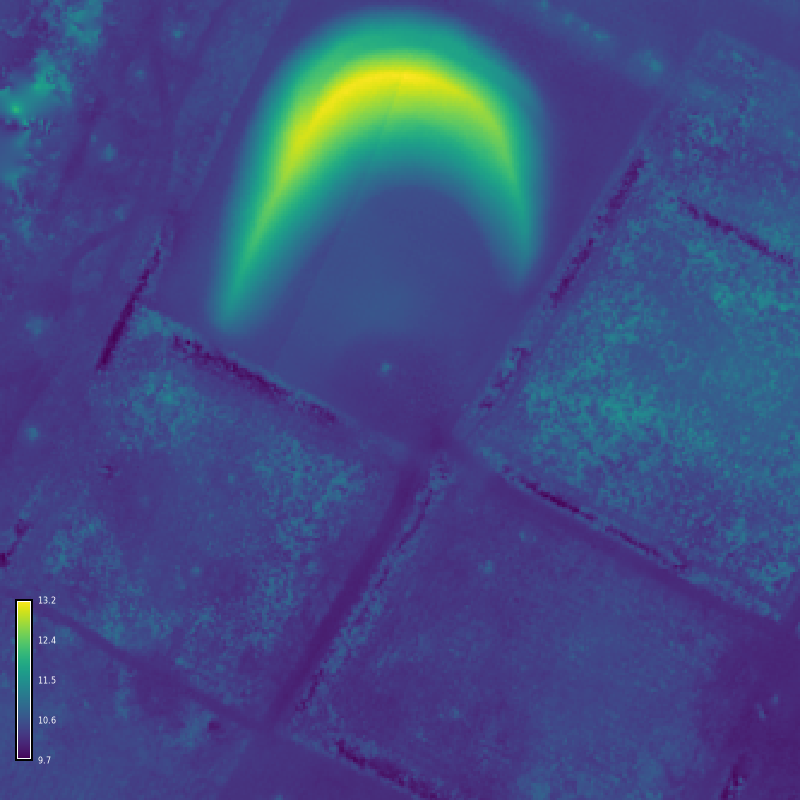

In [11]:
# Interpolate ground
tools.v_surf_rst(
    input="ground",
    elevation="elevation",
    nprocs=32
    )

# Set color gradient
tools.r_colors(map="elevation", color="viridis")

# Visualize
m = gj.Map(width=800)
m.d_rast(map="elevation")
m.d_legend(raster="elevation", color="white", at=(5, 25, 2, 4))
m.show()

## Convert to point cloud

In [13]:
# Import NumPy
import numpy as np

# Convert raster to point cloud
data = tools.r_out_xyz(input="elevation").text
data = [line.split("|") for line in data.splitlines()]
data = np.array(data, dtype=float)

## Plot point clouds

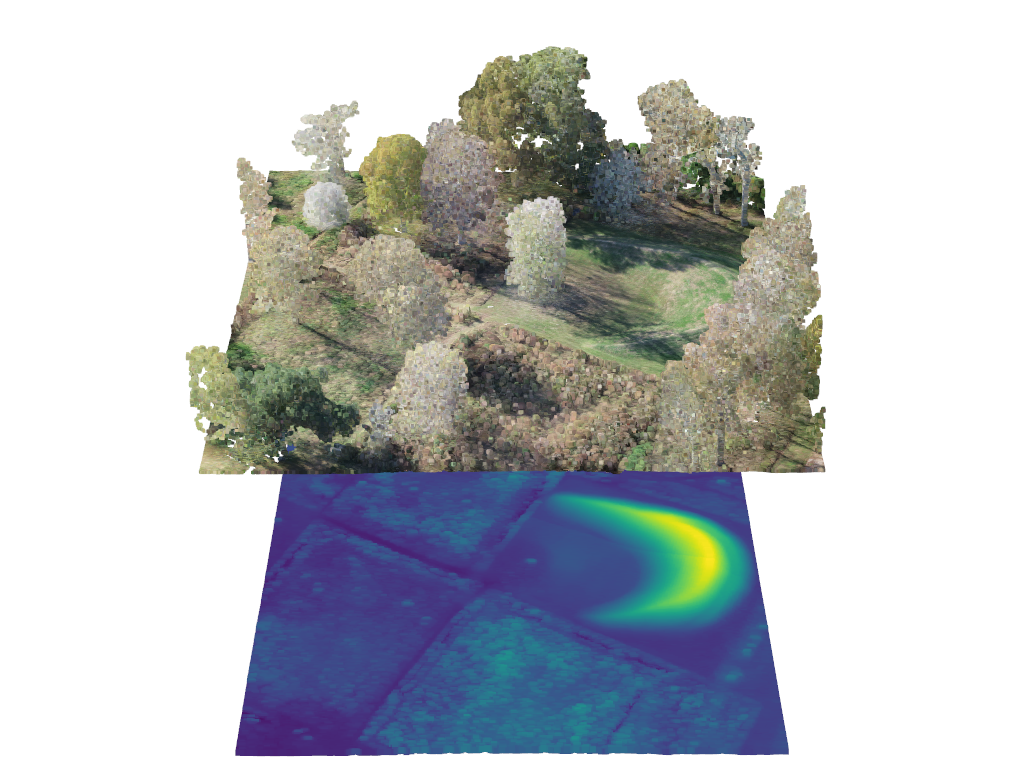

In [27]:
# Import PyVista
import pyvista as pv
import laspy

# Convert ground
ground = pv.PolyData(data)

# Read lidar
lidar = "hilltop.laz"
lidar = laspy.read(lidar)
red = (lidar.red/256).astype("uint8")
green = (lidar.green/256).astype("uint8")
blue = (lidar.blue/256).astype("uint8")
colors = np.column_stack((red, green, blue))
lidar = pv.PolyData(lidar.xyz)

# Shift lidar vertically
lidar = lidar.translate([0.0, 0.0, 65]) 

# Plot point clouds
pv.set_jupyter_backend("static")
pl = pv.Plotter()
pl.add_points(
    lidar.points,
    scalars=colors,
    point_size=3,
    rgba=True,
    )
pl.add_points(
    ground,
    scalars=ground.points[:, 2],
    point_size=6,
    show_scalar_bar=False,
    )
pl.camera_position = "iso"
pl.camera.azimuth += -45
pl.camera.zoom(1.2)
pl.screenshot(filename="lidar-1.png", scale=3, transparent_background=True)
pl.show()